In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

import torchvision.transforms as transforms
import torchvision.models as models

from medmnist import PathMNIST, INFO

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.metrics import confusion_matrix, f1_score


In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)


Using device: cuda


In [3]:
info = INFO["pathmnist"]
num_classes = len(info["label"])

print("Dataset:", info["description"])
print("Classes:", info["label"])


Dataset: The PathMNIST is based on a prior study for predicting survival from colorectal cancer histology slides, providing a dataset (NCT-CRC-HE-100K) of 100,000 non-overlapping image patches from hematoxylin & eosin stained histological images, and a test dataset (CRC-VAL-HE-7K) of 7,180 image patches from a different clinical center. The dataset is comprised of 9 types of tissues, resulting in a multi-class classification task. We resize the source images of 3×224×224 into 3×28×28, and split NCT-CRC-HE-100K into training and validation set with a ratio of 9:1. The CRC-VAL-HE-7K is treated as the test set.
Classes: {'0': 'adipose', '1': 'background', '2': 'debris', '3': 'lymphocytes', '4': 'mucus', '5': 'smooth muscle', '6': 'normal colon mucosa', '7': 'cancer-associated stroma', '8': 'colorectal adenocarcinoma epithelium'}


In [4]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

train_ds = PathMNIST(split="train", transform=transform, download=True)
val_ds   = PathMNIST(split="val",   transform=transform, download=True)
test_ds  = PathMNIST(split="test",  transform=transform, download=True)

print("Train:", len(train_ds))
print("Val:  ", len(val_ds))
print("Test: ", len(test_ds))


Using downloaded and verified file: C:\Users\Acer\.medmnist\pathmnist.npz
Using downloaded and verified file: C:\Users\Acer\.medmnist\pathmnist.npz
Using downloaded and verified file: C:\Users\Acer\.medmnist\pathmnist.npz
Train: 89996
Val:   10004
Test:  7180


In [5]:
train_loader = DataLoader(train_ds, batch_size=64, shuffle=False, num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=64, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=64, shuffle=False, num_workers=2, pin_memory=True)


In [6]:
convnext = models.convnext_tiny(pretrained=True)

for p in convnext.parameters():
    p.requires_grad = False

convnext.classifier = nn.Identity()
convnext = convnext.to(device)
convnext.eval()

gap = nn.AdaptiveAvgPool2d((1, 1))

print("Frozen ConvNeXt-Tiny ready")


D:\python\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
D:\python\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ConvNeXt_Tiny_Weights.IMAGENET1K_V1`. You can also use `weights=ConvNeXt_Tiny_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Frozen ConvNeXt-Tiny ready


In [7]:
def cache_features(backbone, loader, split_name):
    all_feats = []
    all_labels = []

    start = time.time()

    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            y = y.squeeze().long()

            feats = backbone(x)      # [B, 768, H, W]
            feats = gap(feats)       # [B, 768, 1, 1]
            feats = feats.flatten(1) # [B, 768]

            all_feats.append(feats.cpu())
            all_labels.append(y)

    X = torch.cat(all_feats)
    y = torch.cat(all_labels)

    torch.save(
        {"X": X, "y": y},
        f"convnext_tiny_{split_name}_features.pth"
    )

    print(f"✔ Cached {split_name} features | shape: {X.shape} | time: {round(time.time()-start,2)}s")


In [8]:
cache_features(convnext, train_loader, "train")
cache_features(convnext, val_loader,   "val")
cache_features(convnext, test_loader,  "test")


✔ Cached train features | shape: torch.Size([89996, 768]) | time: 848.88s
✔ Cached val features | shape: torch.Size([10004, 768]) | time: 82.23s
✔ Cached test features | shape: torch.Size([7180, 768]) | time: 60.67s


In [9]:
train_data = torch.load("convnext_tiny_train_features.pth")
val_data   = torch.load("convnext_tiny_val_features.pth")
test_data  = torch.load("convnext_tiny_test_features.pth")

X_train, y_train = train_data["X"], train_data["y"]
X_val,   y_val   = val_data["X"],   val_data["y"]
X_test,  y_test  = test_data["X"],  test_data["y"]

print("Train feats:", X_train.shape)
print("Val feats:  ", X_val.shape)
print("Test feats: ", X_test.shape)


C:\Users\Acer\AppData\Local\Temp\ipykernel_23896\4003368999.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  train_data = torch.load("convnext_tiny_train_features.pth")


Train feats: torch.Size([89996, 768])
Val feats:   torch.Size([10004, 768])
Test feats:  torch.Size([7180, 768])


C:\Users\Acer\AppData\Local\Temp\ipykernel_23896\4003368999.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  val_data   = torch.load("convnext_tiny_val_features.pth")
C:\

In [10]:
train_loader = DataLoader(
    TensorDataset(X_train, y_train),
    batch_size=64,
    shuffle=True
)

val_loader = DataLoader(
    TensorDataset(X_val, y_val),
    batch_size=64,
    shuffle=False
)

test_loader = DataLoader(
    TensorDataset(X_test, y_test),
    batch_size=64,
    shuffle=False
)


In [11]:
linear_probe = nn.Linear(768, num_classes).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(linear_probe.parameters(), lr=1e-3)

epochs = 30


In [12]:
def run_epoch_linear(head, loader, train=False):
    head.train() if train else head.eval()

    total_loss = 0
    correct = 0
    total = 0

    for x, y in loader:
        x = x.to(device)
        y = y.to(device)

        outputs = head(x)
        loss = criterion(outputs, y)

        if train:
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        total_loss += loss.item() * y.size(0)
        correct += (outputs.argmax(1) == y).sum().item()
        total += y.size(0)

    return total_loss / total, 100 * correct / total


In [60]:
import time

train_losses, val_losses = [], []
train_accs, val_accs = [], []
epoch_times = []

num_epochs = 30

print(f"{'Epoch':<8} | {'Train Loss':<12} | {'Train Acc':<12} | {'Val Loss':<12} | {'Val Acc':<12} | {'Time':<10}")
print("-" * 90)

for epoch in range(num_epochs):
    start_time = time.time()

    train_loss, train_acc = run_epoch_linear(linear_probe, train_loader, train=True)
    val_loss, val_acc = run_epoch_linear(linear_probe, val_loader, train=False)

    elapsed_time = time.time() - start_time

    # store raw values (0–1)
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)
    epoch_times.append(elapsed_time)

    print(
        f"{epoch+1:<8} | "
        f"{train_loss:<12.4f} | "
        f"{train_acc:<12.4f} | "
        f"{val_loss:<12.4f} | "
        f"{val_acc:<12.4f} | "
        f"{elapsed_time:<8.2f}s"
    )

total_training_time = sum(epoch_times)
print(f"\nTotal Training Time: {total_training_time/60:.2f} minutes")

Epoch    | Train Loss   | Train Acc    | Val Loss     | Val Acc      | Time      
------------------------------------------------------------------------------------------
1        | 0.1786       | 94.1108      | 0.1925       | 93.4526      | 5.72    s
2        | 0.1785       | 94.0497      | 0.1921       | 93.6525      | 5.66    s
3        | 0.1782       | 94.0986      | 0.1928       | 93.6725      | 5.54    s
4        | 0.1779       | 94.1264      | 0.1932       | 93.5426      | 5.32    s
5        | 0.1777       | 94.1397      | 0.1915       | 93.6325      | 5.60    s
6        | 0.1774       | 94.1197      | 0.1916       | 93.6925      | 5.63    s
7        | 0.1771       | 94.0908      | 0.1921       | 93.4426      | 5.33    s
8        | 0.1773       | 94.1075      | 0.1931       | 93.5726      | 5.44    s
9        | 0.1769       | 94.1542      | 0.1921       | 93.6525      | 5.57    s
10       | 0.1767       | 94.1286      | 0.1947       | 93.4526      | 5.37    s
11       | 0.1767

In [61]:
test_loss, test_acc = run_epoch_linear(linear_probe, test_loader)

print("\n===== FINAL TEST RESULT =====")
print(f"Test Accuracy: {test_acc:.2f}%")



===== FINAL TEST RESULT =====
Test Accuracy: 89.33%


In [62]:
linear_probe.eval()

with torch.no_grad():
    y_pred = torch.cat([
        linear_probe(x.to(device)).argmax(1).cpu()
        for x, _ in test_loader
    ])


In [63]:
y_true = y_test.numpy()
y_pred = y_pred.numpy()


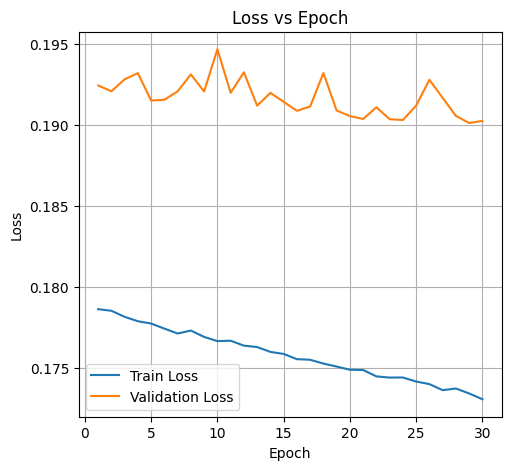

In [66]:
import matplotlib.pyplot as plt

epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(12,5))

# -------------------------
# Loss Plot
# -------------------------
plt.subplot(1,2,1)
plt.plot(epochs, train_losses, label="Train Loss")
plt.plot(epochs, val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss vs Epoch")
plt.legend()
plt.grid()


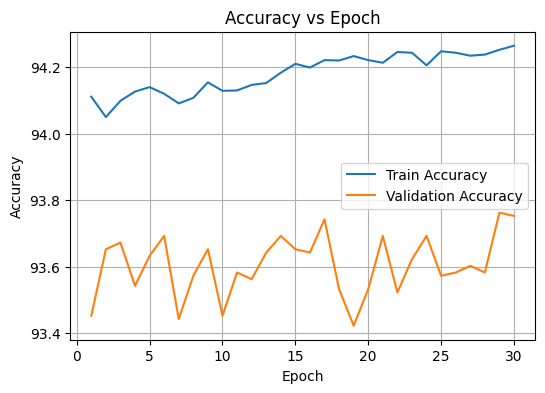

In [67]:
import matplotlib.pyplot as plt
import numpy as np

epochs = range(1, len(train_accs) + 1)

plt.figure(figsize=(6,4))

plt.plot(epochs, train_accs, label="Train Accuracy")
plt.plot(epochs, val_accs, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy vs Epoch")
plt.legend()
plt.grid()

plt.show()

In [68]:
classwise_accuracy = {}

for cls in range(num_classes):
    mask = (y_true == cls)
    acc = (y_pred[mask] == cls).mean()
    classwise_accuracy[cls] = acc
    print(f"Class {cls} accuracy: {acc:.4f}")


Class 0 accuracy: 0.9828
Class 1 accuracy: 1.0000
Class 2 accuracy: 0.4867
Class 3 accuracy: 0.9621
Class 4 accuracy: 0.9536
Class 5 accuracy: 0.8024
Class 6 accuracy: 0.9298
Class 7 accuracy: 0.4584
Class 8 accuracy: 0.9189


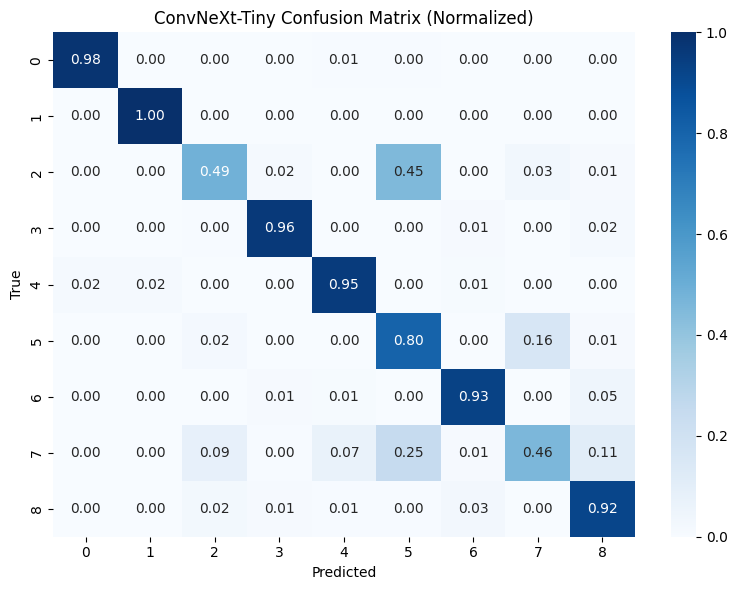

In [70]:
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(8,6))
sns.heatmap(
    cm_norm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=range(num_classes),
    yticklabels=range(num_classes)
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("ConvNeXt-Tiny Confusion Matrix (Normalized)")
plt.tight_layout()
plt.show()


In [57]:
macro_f1 = f1_score(y_true, y_pred, average="macro")
print("Macro-F1:", round(macro_f1, 4))


Macro-F1: 0.8345


In [58]:
torch.save(
    linear_probe.state_dict(),
    "convnext_tiny_linear_probe.pth"
)


In [59]:
torch.save(
    {
        "model": "Frozen ConvNeXt-Tiny + Linear Probe",
        "dataset": "PathMNIST",
        "test_accuracy": test_acc,
        "macro_f1": macro_f1,
        "classwise_accuracy": classwise_accuracy,
        "confusion_matrix": cm
    },
    "convnext_tiny_test_metrics.pth"
)

print("✔ Model and metrics saved")


✔ Model and metrics saved


In [71]:
from sklearn.metrics import classification_report

# 1. Generate the classification report
# Ensure y_true and y_pred are already defined (which they are in your cell [70])
report = classification_report(y_true, y_pred, digits=4)

print("--- ConvNeXt-Tiny Classification Summary ---")
print(report)

# 2. Optional: If you want to see the specific Macro-F1 you calculated earlier
from sklearn.metrics import f1_score
macro_f1 = f1_score(y_true, y_pred, average="macro")
print(f"Final Macro-F1 Score: {macro_f1:.4f}")

--- ConvNeXt-Tiny Classification Summary ---
              precision    recall  f1-score   support

           0     0.9865    0.9828    0.9846      1338
           1     0.9747    1.0000    0.9872       847
           2     0.6600    0.4867    0.5603       339
           3     0.9502    0.9621    0.9561       634
           4     0.9472    0.9536    0.9504      1035
           5     0.6376    0.8024    0.7105       592
           6     0.9102    0.9298    0.9199       741
           7     0.6370    0.4584    0.5331       421
           8     0.9144    0.9189    0.9167      1233

    accuracy                         0.8933      7180
   macro avg     0.8464    0.8328    0.8354      7180
weighted avg     0.8913    0.8933    0.8900      7180

Final Macro-F1 Score: 0.8354
